# 04. Benchmark, leakage audit and controls

This notebook only **displays** results produced by the pipeline (`python reproduce_all.py`). All numbers come from `results/metrics/benchmark_*_folds.csv`; nothing here is typed by hand.

**Question.** Using only covariates that are observable *before* knowing whether a spring dried (primary feature set `env`), how well can drying be predicted, and do graph neural networks add anything over graph-free models?

In [1]:
import os, sys
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## 1. Survey skip-logic leakage
Fields from questionnaire sections skipped for dried sources are (almost) perfectly missing for dried springs. A single such indicator predicts the label.

,column,missing_active,missing_dried,missingness_gap,skip_logic_leak
0,reason_of_drying,1.00000,0.000000,-1.000000,True
1,water_quality,0.00000,1.000000,1.000000,True
2,water_quality_ordinal,0.00000,1.000000,1.000000,True
3,has_user_group,0.00000,1.000000,1.000000,True
4,in_use,0.00000,1.000000,1.000000,True
5,water_quality_change,0.00000,1.000000,1.000000,True
6,Is this source in use?_binary,0.00000,1.000000,1.000000,True
7,Are there water user groups for management?_bi...,0.00000,1.000000,1.000000,True
8,years_since_dried,0.99976,0.000000,-0.999760,True
9,cultural_significance,0.00048,1.000000,0.999520,True


,feature,single_feature_auc
0,earthquake_impact_ordinal,0.958373
1,earthquake_impact_known,0.958373
2,Perennial / Seasonal_encoded,0.651818
3,longitude,0.611273
4,precip_monsoon_mm,0.607642
5,precip_annual_mm,0.605170
6,ndvi_mean,0.587662
7,elevation_m,0.586982


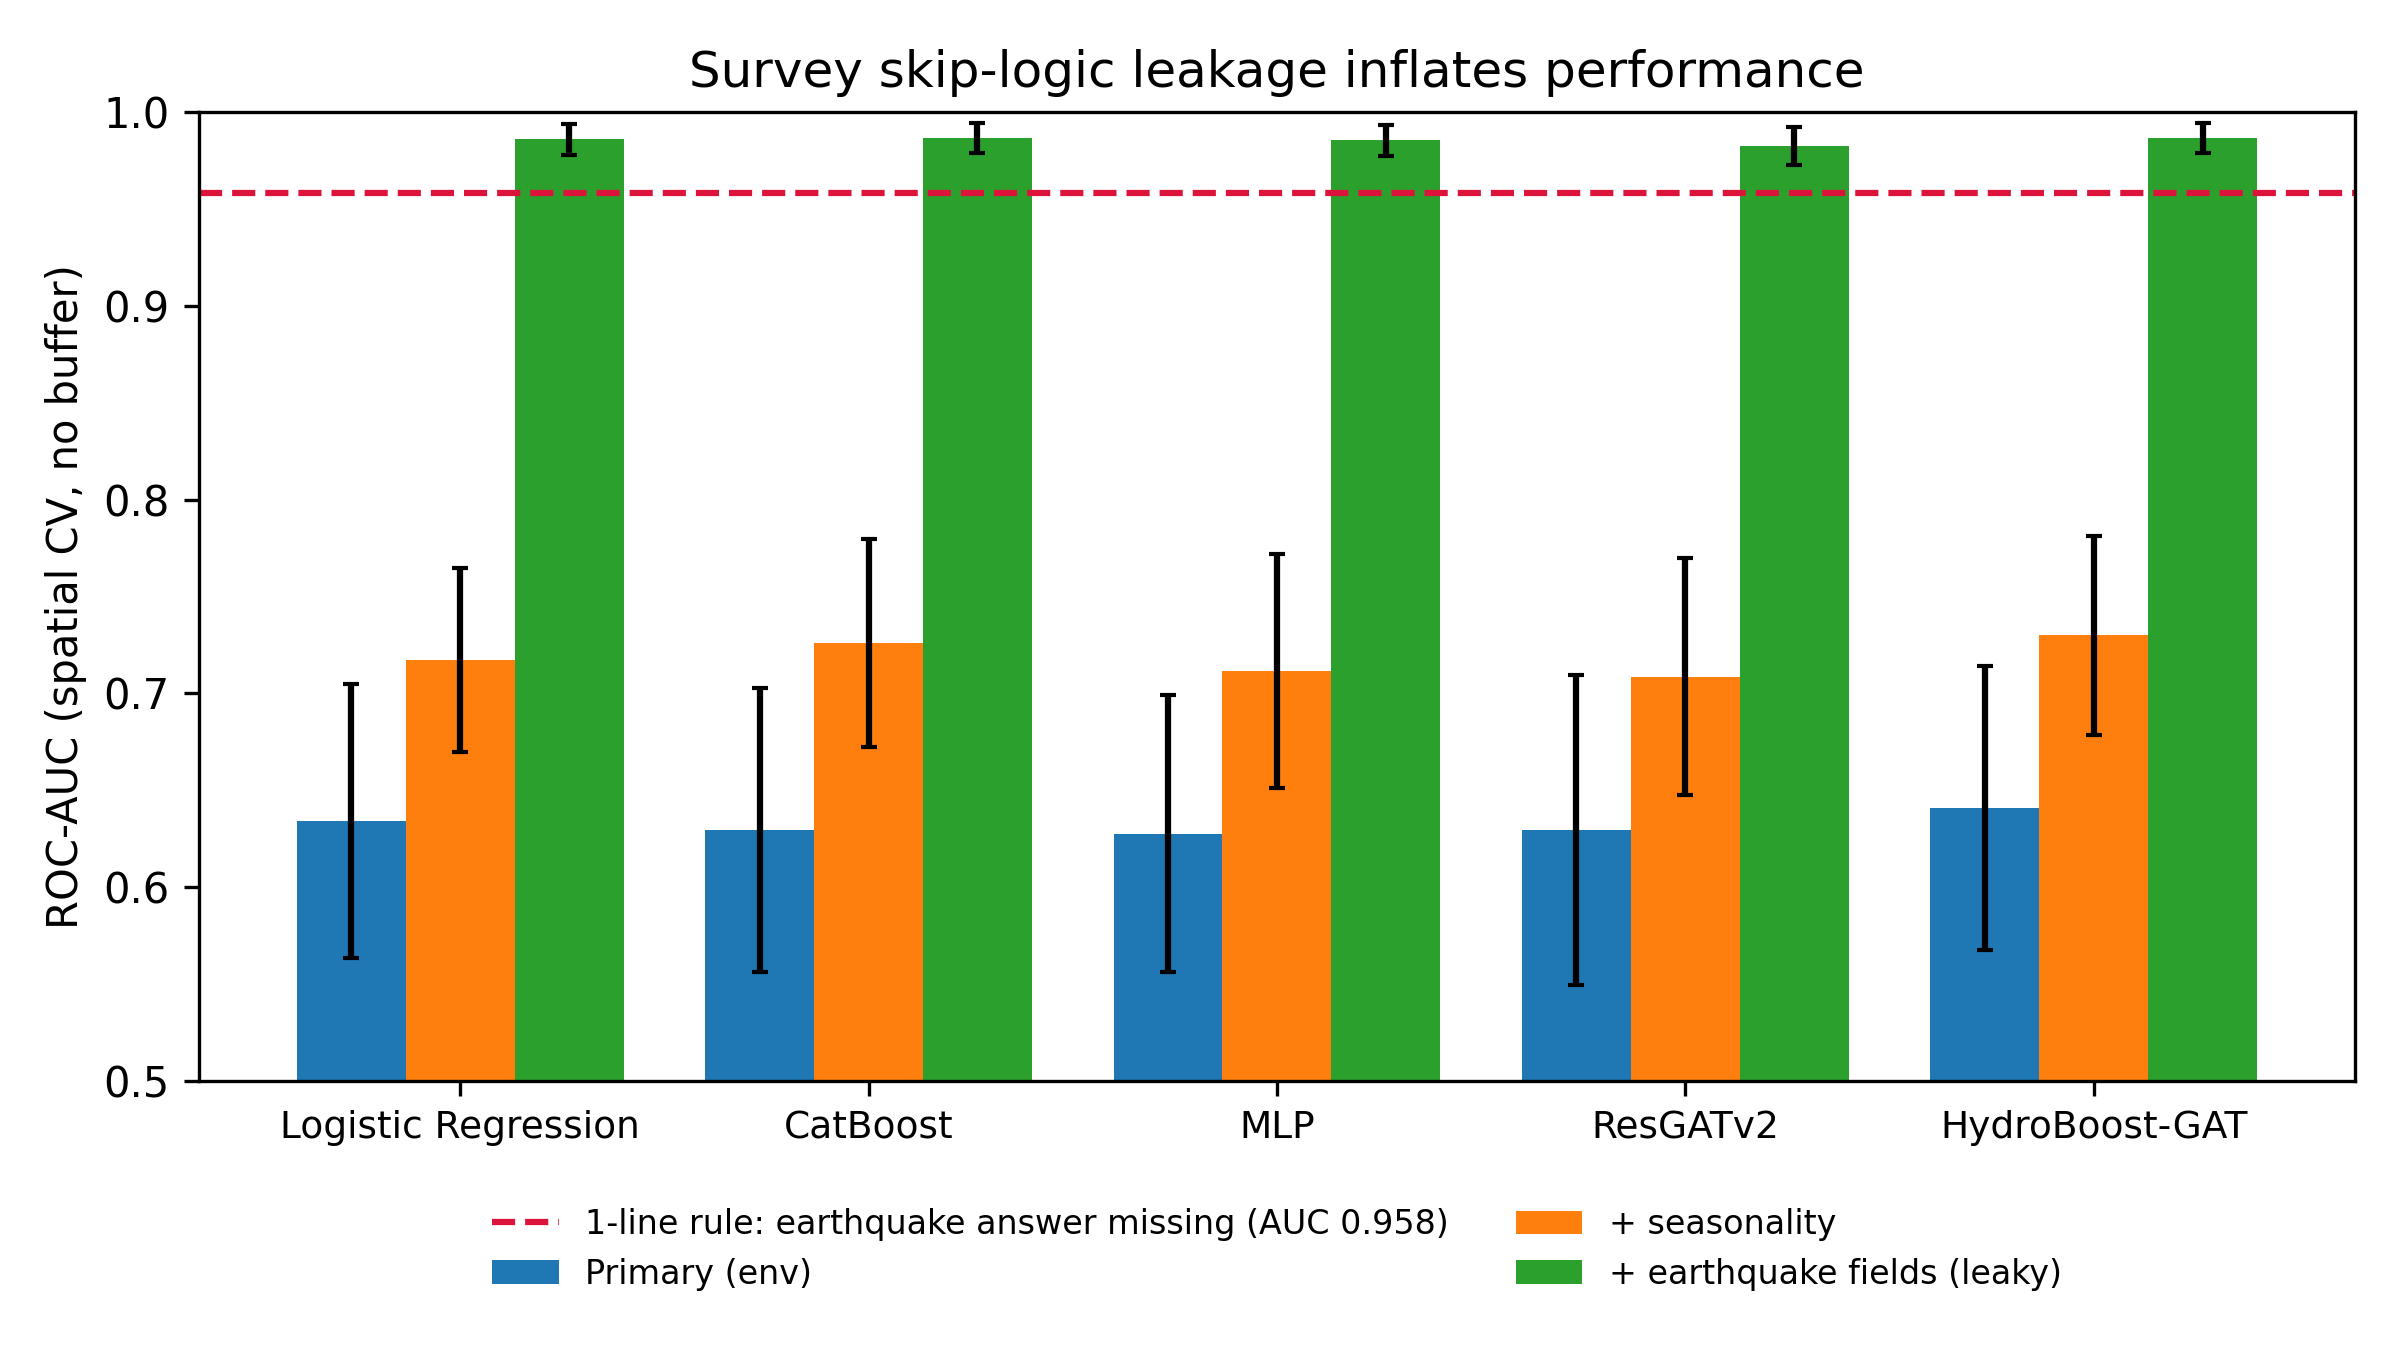

In [2]:
audit = pd.read_csv('results/metrics/leakage_audit.csv')
display(audit[audit.skip_logic_leak].head(15))
display(pd.read_csv('results/metrics/single_feature_auc.csv').head(8))
display(Image('results/figures/leakage_feature_sets.png'))

## 2. Benchmark on the primary (leak-free) feature set
Spatial block 5-fold CV (5 seeds) with no buffer (interpolation) and a 500 m buffer (extrapolation), plus leave-one-municipality-out.

,profile,buffer_m,model,n_folds,roc_auc_mean,roc_auc_sd,pr_auc_mean,f1_macro_mean,bal_acc_mean,brier_mean
13,lomo,500.0,Logistic Regression,21,0.588,0.030,0.330,0.504,0.534,0.234
15,lomo,500.0,Random Forest,21,0.584,0.058,0.335,0.487,0.539,0.199
12,lomo,500.0,HydroBoost-GAT,21,0.581,0.034,0.329,0.498,0.532,0.229
10,lomo,500.0,CatBoost,21,0.581,0.038,0.329,0.492,0.535,0.232
14,lomo,500.0,MLP,21,0.567,0.042,0.322,0.494,0.532,0.240
16,lomo,500.0,ResGATv2,21,0.554,0.052,0.311,0.498,0.529,0.250
11,lomo,500.0,GraphSAGE,21,0.545,0.063,0.301,0.481,0.524,0.250
17,lomo,500.0,kNN label interpolation,21,0.513,0.071,0.282,0.445,0.496,0.244
24,main,0.0,HydroBoost-GAT,25,0.641,0.057,0.397,0.562,0.585,0.220
22,main,0.0,"HydroBoost | CatBoost + GAT, no diffusion",25,0.639,0.058,0.394,0.558,0.582,0.221


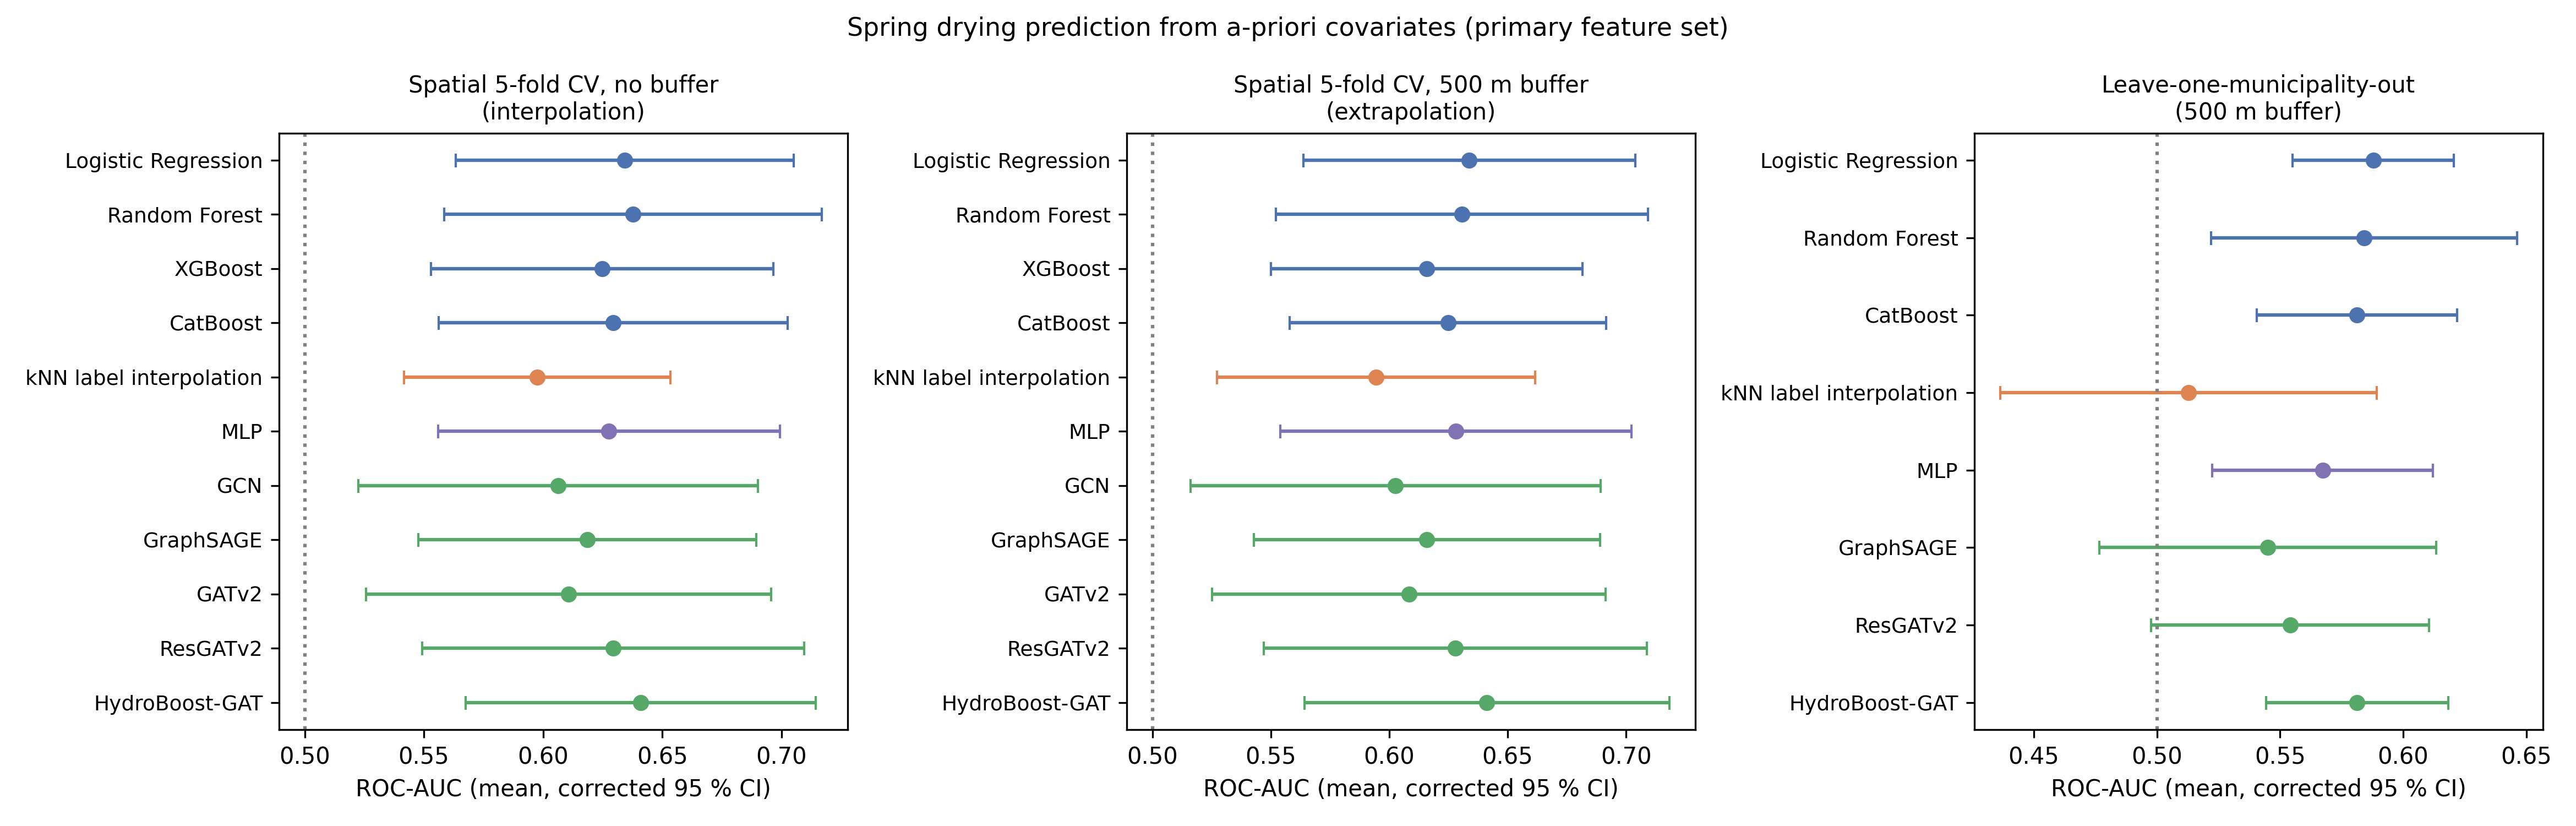

In [3]:
s = pd.read_csv('results/metrics/benchmark_summary.csv')
cols = ['profile','buffer_m','model','n_folds','roc_auc_mean','roc_auc_sd','pr_auc_mean','f1_macro_mean','bal_acc_mean','brier_mean']
prim = s[s.feature_set=='env'].sort_values(['profile','buffer_m','roc_auc_mean'], ascending=[True,True,False])
display(prim[cols].round(3))
display(Image('results/figures/model_benchmark_comparison.png'))

## 3. Paired tests against the best graph-free model
Corrected resampled t-test (Nadeau & Bengio, 2003), Holm-adjusted.

In [4]:
t = pd.read_csv('results/metrics/paired_tests_vs_best_tabular.csv')
display(t[(t.metric=='roc_auc') & (t.feature_set=='env')].round(4))

,profile,scheme,feature_set,buffer_m,metric,reference,model,mean_diff,ci95_low,ci95_high,wins,n_pairs,t_corrected,p_corrected,p_holm
8,lomo,lomo,env,500.0,roc_auc,Logistic Regression,Random Forest,-0.0037,-0.0719,0.0645,11,21,-0.1127,0.9114,1.0000
9,lomo,lomo,env,500.0,roc_auc,Logistic Regression,CatBoost,-0.0066,-0.0505,0.0372,10,21,-0.3153,0.7558,1.0000
10,lomo,lomo,env,500.0,roc_auc,Logistic Regression,kNN label interpolation,-0.0750,-0.1500,-0.0001,4,21,-2.0881,0.0498,0.3485
11,lomo,lomo,env,500.0,roc_auc,Logistic Regression,MLP,-0.0205,-0.0578,0.0168,4,21,-1.1454,0.2656,1.0000
12,lomo,lomo,env,500.0,roc_auc,Logistic Regression,GraphSAGE,-0.0428,-0.1044,0.0187,5,21,-1.4507,0.1624,0.8817
13,lomo,lomo,env,500.0,roc_auc,Logistic Regression,ResGATv2,-0.0337,-0.0802,0.0129,4,21,-1.5089,0.1470,0.8817
14,lomo,lomo,env,500.0,roc_auc,Logistic Regression,HydroBoost-GAT,-0.0065,-0.0388,0.0258,9,21,-0.4216,0.6778,1.0000
15,main,spatial,env,0.0,roc_auc,Random Forest,Logistic Regression,-0.0035,-0.0472,0.0403,9,25,-0.1633,0.8716,1.0000
16,main,spatial,env,0.0,roc_auc,Random Forest,XGBoost,-0.0128,-0.0474,0.0218,9,25,-0.7660,0.4512,1.0000
17,main,spatial,env,0.0,roc_auc,Random Forest,CatBoost,-0.0082,-0.0294,0.0130,7,25,-0.7994,0.4319,1.0000


## 4. Ablations and negative controls

,profile,scheme,feature_set,buffer_m,metric,reference,model,mean_diff,ci95_low,ci95_high,wins,n_pairs,t_corrected,p_corrected,p_holm
0,main,spatial,env,0.0,roc_auc,ResGATv2,ResGATv2 - no edge attributes,0.0001,-0.0378,0.0379,12,25,0.0030,0.9976,1.0000
1,main,spatial,env,0.0,roc_auc,ResGATv2,ResGATv2 - no ego skip,-0.0179,-0.0603,0.0244,8,25,-0.8739,0.3908,1.0000
2,main,spatial,env,0.0,roc_auc,ResGATv2,ResGATv2 + LayerNorm,-0.0060,-0.0214,0.0094,6,25,-0.8065,0.4279,1.0000
3,main,spatial,env,0.0,roc_auc,ResGATv2,ResGATv2 (2 layers),-0.0105,-0.0561,0.0350,14,25,-0.4770,0.6377,1.0000
4,main,spatial,env,0.0,roc_auc,ResGATv2,ResGATv2 | placebo: shuffled edge attributes,-0.0001,-0.0102,0.0100,14,25,-0.0177,0.9860,1.0000
5,main,spatial,env,0.0,roc_auc,ResGATv2,ResGATv2 | placebo: random topology,-0.0067,-0.0400,0.0267,13,25,-0.4141,0.6825,1.0000
6,main,spatial,env,500.0,roc_auc,ResGATv2,ResGATv2 - no edge attributes,0.0024,-0.0371,0.0419,12,25,0.1246,0.9019,1.0000
7,main,spatial,env,500.0,roc_auc,ResGATv2,ResGATv2 - no ego skip,-0.0117,-0.0546,0.0312,11,25,-0.5621,0.5793,1.0000
8,main,spatial,env,500.0,roc_auc,ResGATv2,ResGATv2 + LayerNorm,-0.0052,-0.0224,0.0120,9,25,-0.6290,0.5353,1.0000
9,main,spatial,env,500.0,roc_auc,ResGATv2,ResGATv2 (2 layers),-0.0214,-0.0865,0.0437,10,25,-0.6773,0.5047,1.0000


,profile,feature_set,buffer_m,folds,mean_w_catboost,share_w0,share_w1,share_no_diffusion
0,features,env_season,0.0,25,0.520,0.080,0.12,0.040
1,features,leaky_reference,0.0,25,0.760,0.000,0.28,0.360
2,lomo,env,500.0,21,0.486,0.095,0.19,0.095
3,main,env,0.0,25,0.352,0.200,0.08,0.040
4,main,env,500.0,25,0.352,0.200,0.04,0.000


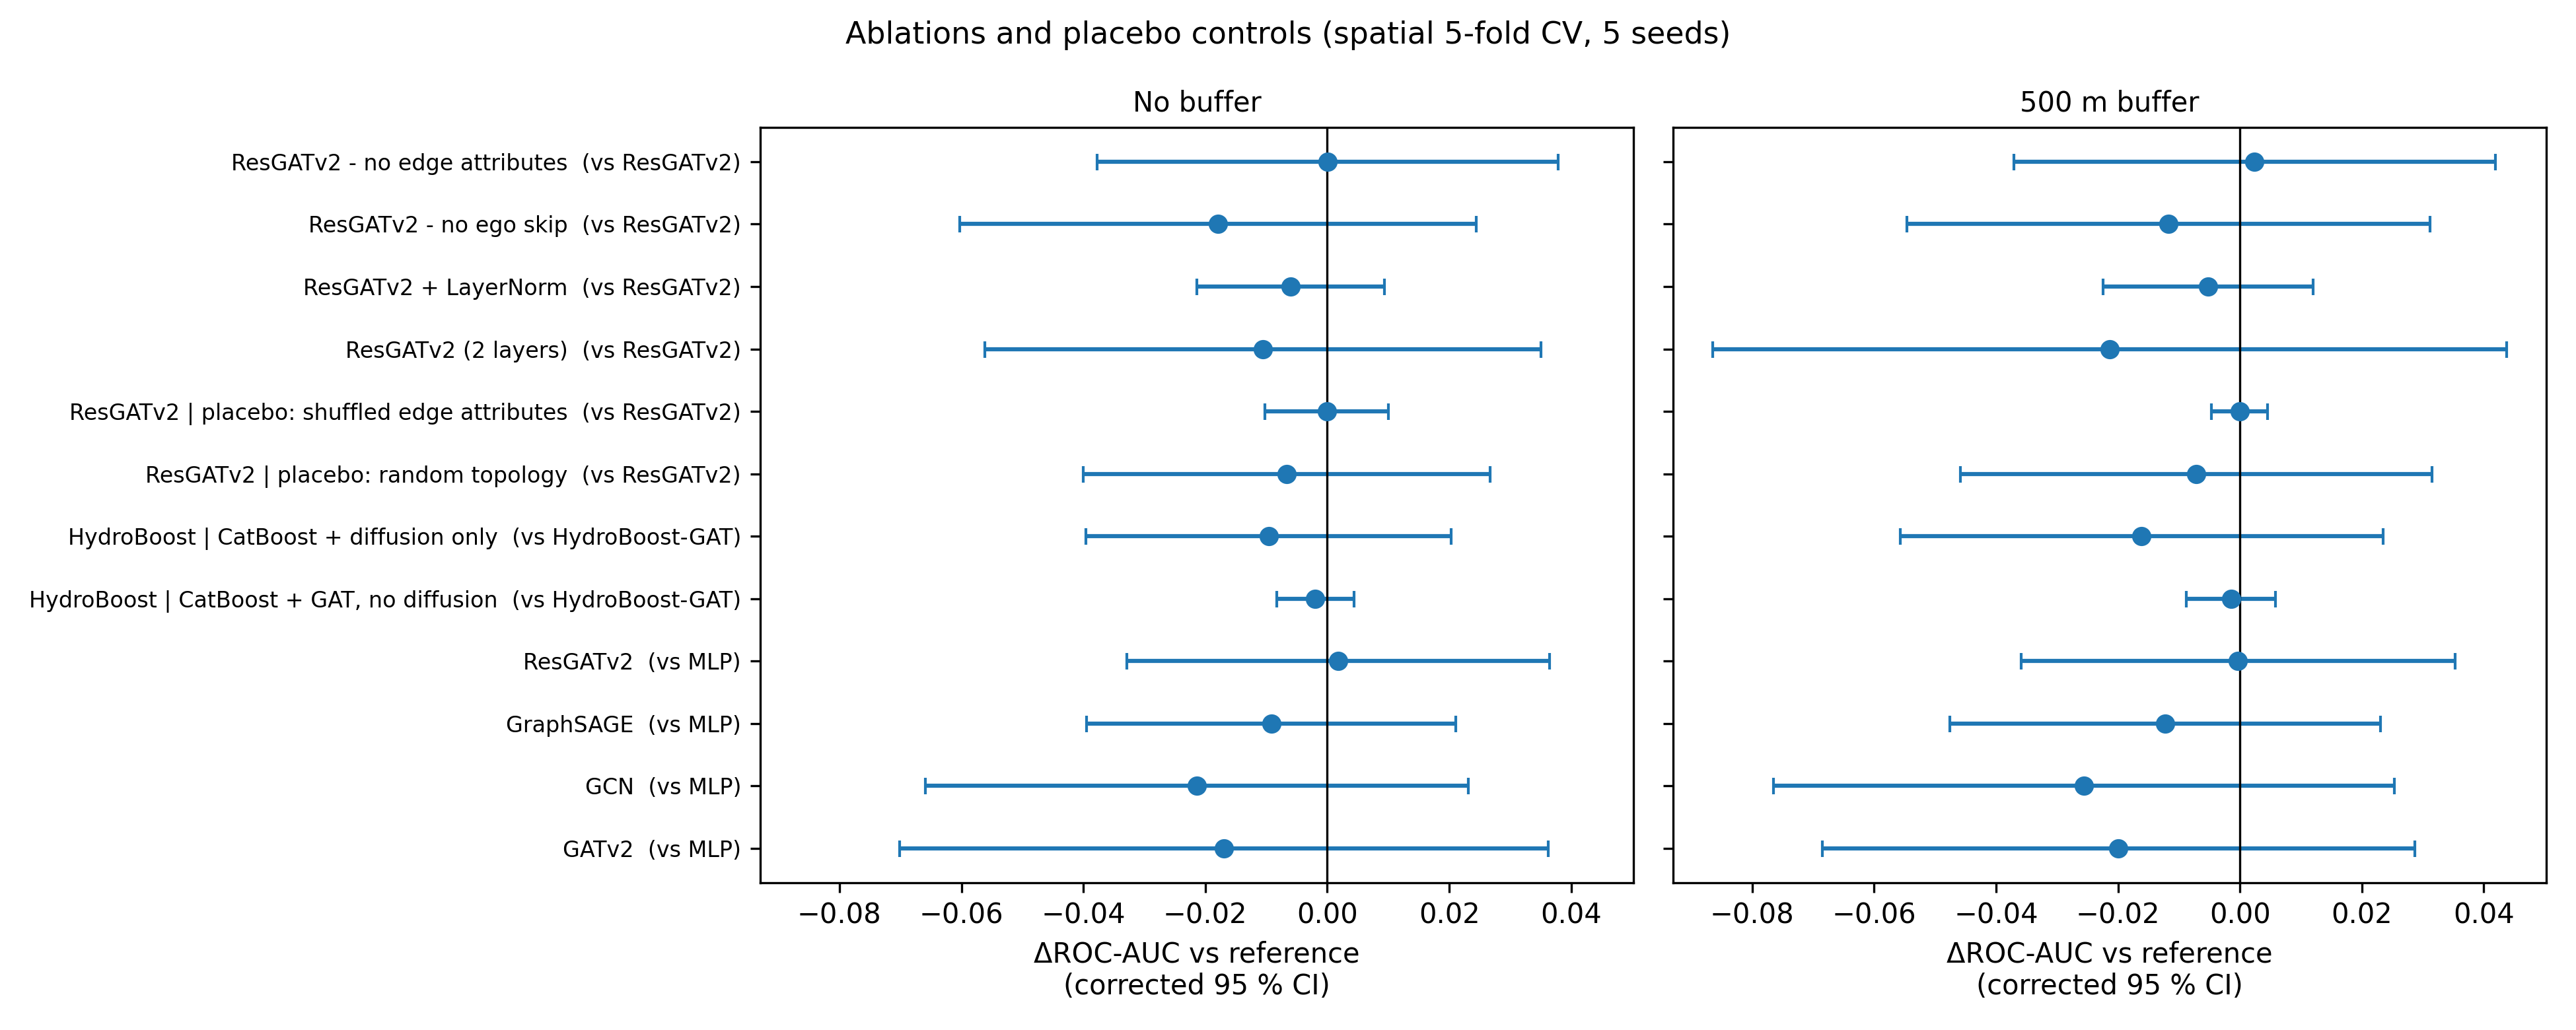

In [5]:
display(pd.read_csv('results/metrics/ablation_and_placebo_tests.csv').round(4))
display(pd.read_csv('results/metrics/hydroboost_selection_summary.csv').round(3))
display(Image('results/figures/ablation_controls.png'))

## 5. Leave-one-municipality-out per municipality

In [6]:
display(pd.read_csv('results/tables/lomo_per_municipality_auc.csv'))

,Held-out municipality,N,dried,Drying rate,Logistic Regression,Random Forest,CatBoost,kNN label interpolation,MLP,GraphSAGE,ResGATv2,HydroBoost-GAT
0,Bethanchownk,385,74,19.2%,0.615,0.496,0.568,0.541,0.557,0.554,0.581,0.597
1,Dhulikhel,1174,338,28.8%,0.623,0.577,0.559,0.501,0.625,0.604,0.607,0.585
2,Namobuudha,478,96,20.1%,0.552,0.551,0.552,0.562,0.533,0.509,0.522,0.547
3,Panauti,880,83,9.4%,0.613,0.643,0.629,0.520,0.592,0.558,0.539,0.593
4,Panchkhal,1067,426,39.9%,0.589,0.659,0.634,0.623,0.586,0.619,0.590,0.626
5,Roshi RM,969,211,21.8%,0.563,0.614,0.574,0.416,0.561,0.522,0.551,0.565
6,Temal,736,293,39.8%,0.559,0.548,0.554,0.426,0.518,0.449,0.489,0.556
